## Experiment for the SoCG paper

This experiment has two goals: 
1. compute how many duplicates vs non duplicate switch points there are 
2. compute as a function of number of points how the number of switch points grows 

We start first with the number of points in each modules being balanced


In [78]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools
from scipy.stats import qmc
import math
import random as rnd

import pickle as pkl

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [79]:
Omega_counts = {}
algo_names = ['2v2p', '2v2u','3v1']
poisson_intensity = 1
for i in range(1,3): 
    Omega_counts[(i,'d')] = [[],[],[]]
    Omega_counts[(i,'u')] = [[],[],[]]

In [80]:
max_num = 10

Omega_counts = {}
seeds = [0,1,2,3,4,5,6,7,8,9]

algo_names = ['2v2p', '2v2u','3v1']
poisson_intensity = 1

for i in range(1,max_num+1): 
    Omega_counts[(i,'d')] = [[],[],[]]
    Omega_counts[(i,'u')] = [[],[],[]]


for exact_num in range(1,max_num+1):
    for seed in seeds:
    
        CritPts = ex.make_rects_balanced(poisson_intensity, seed=seed, exact_num=exact_num)
        name = 'Counts/rects_balanced_r' + str(exact_num)+ '_s' + str(seed)
    

        Pts2_2_paired, num_dup2_2_paired, num_pts2_2_paired, _ , _ = omega.output_alg_2_2_paired(CritPts, name) 
        Pts2_2_unpaired, num_dup2_2_unpaired, num_pts2_2_unpaired, _ , _ = omega.output_alg_2_2_unpaired(CritPts, name)
        Pts3_1, num_dup3_1, num_pts3_1 = omega.output_alg_3_1(CritPts, name)

        Omega_counts[(exact_num,'d')][0].append(num_dup2_2_paired)
        Omega_counts[(exact_num,'d')][1].append(num_dup2_2_unpaired)
        Omega_counts[(exact_num,'d')][2].append(num_dup3_1)

        Omega_counts[(exact_num,'u')][0].append(num_pts2_2_paired)
        Omega_counts[(exact_num,'u')][1].append(num_pts2_2_unpaired)
        Omega_counts[(exact_num,'u')][2].append(num_pts3_1)

    

# save data
with open('../output/Counts/Omega_counts_rectanlges.pkl', 'wb') as f:
    pkl.dump(Omega_counts, f)

    






**********
Computed 48 points (with duplicates)
Without duplicates 12
['m', 1.2467039779012516, 0.25329602209874835, 0.2699954143142199, 2.8453858975649466, 0.5781042989871366, 0.75, 1.7117450982760418, 0.08620937605105256, 0.5113320800266262, 0.10388864087869472, 1.0131840883949934, 0.3076103604526605]
['omega_pts', (0, 8.0, 9.973631823210013), (0, 8.0, 2.026368176789987), (0, 3.7525973949166875, 1.0131840883949934), (0, 1.7525973949166875, 4.986815911605007), (0, 1.7525973949166875, 1.0131840883949934), (0, 16.0, 12.0), (0, 3.505194789833375, 6.0), (0, 11.752597394916688, 1.0131840883949934), (0, 9.752597394916688, 4.986815911605007), (0, 9.752597394916688, 1.0131840883949934), (0, 2.0, 2.026368176789987), (0, 19.505194789833375, 6.0)]
**********
Computed 126 points (with duplicates)
Without duplicates 30
['m', None, None, None, 0.2699954143142199, None, None, 0.5781042989871366, None, None, 0.75, None, None, None, None, None, None, None, 0.08620937605105256, None, 0.1038886408786947

## Plots 

In [ ]:
Omega_counts[(1,'u')]

[[12, 9], [30, 28], [61, 56]]

2v2p
[10.5, 367.5]
[1 2]


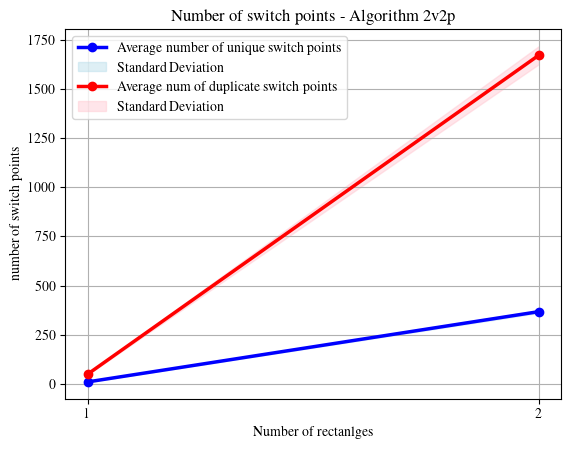

In [44]:
## make plot with my data 
alg_num = 0
print(algo_names[alg_num])

Omega_counts[(1,'u')]

# Calculate averages and standard deviations
averages_u = [np.mean(Omega_counts[(i,'u')][alg_num]) for i in range(1, max_num+1)]

print(averages_u)
std_devs_u = [np.std(Omega_counts[(i,'u')][alg_num]) for i in range(1, max_num+1)]

averages_d = [np.mean(Omega_counts[(i,'d')][alg_num]) for i in range(1, max_num+1)]
std_devs_d = [np.std(Omega_counts[(i,'d')][alg_num]) for i in range(1, max_num+1)]

# Plotting
x = np.arange(1, max_num+1)  # Integers from 1 to 5

print(x)

plt.plot(x, averages_u, marker='o', linestyle='-', color='blue', linewidth=2.5, label='Average number of unique switch points')  # Thicker line for average

plt.fill_between(x, np.array(averages_u) - np.array(std_devs_u), np.array(averages_u) + np.array(std_devs_u),
                 color='lightblue', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds

plt.plot(x, averages_d, marker='o', linestyle='-', color='red', linewidth=2.5, label='Average num of duplicate switch points')  # Thicker line for average

plt.fill_between(x, np.array(averages_d) - np.array(std_devs_d), np.array(averages_d) + np.array(std_devs_d),
                    color='pink', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds


plt.xlabel('Number of rectanlges')
plt.ylabel('number of switch points')
plt.title('Number of switch points - Algorithm '+ str(algo_names[alg_num]))
plt.xticks(x)
plt.legend()
plt.grid(True)
plt.show()



In [47]:
def plot_switch_pts_rectangles(Omega_counts, algo_names, max_num, alg_num):
    """Plot the average number of switch points""" 
    ## make plot with my data 

    print(algo_names[alg_num])

    # Calculate averages and standard deviations
    averages_u = [np.mean(Omega_counts[(i,'u')][alg_num]) for i in range(1, max_num+1)]

    print(averages_u)
    std_devs_u = [np.std(Omega_counts[(i,'u')][alg_num]) for i in range(1, max_num+1)]
    print(std_devs_u)
    

    averages_d = [np.mean(Omega_counts[(i,'d')][alg_num]) for i in range(1, max_num+1)]
    std_devs_d = [np.std(Omega_counts[(i,'d')][alg_num]) for i in range(1, max_num+1)]
    print(averages_d)
    print(std_devs_d)
    # Plotting
    x = np.arange(1, max_num+1)  # Integers from 1 to 5

    plt.plot(x, averages_u, marker='o', linestyle='-', color='blue', linewidth=2.5, label='Average number of unique switch points')  # Thicker line for average

    plt.fill_between(x, np.array(averages_u) - np.array(std_devs_u), np.array(averages_u) + np.array(std_devs_u),
                    color='lightblue', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds

    plt.plot(x, averages_d, marker='o', linestyle='-', color='red', linewidth=2.5, label='Average num of duplicate switch points')  # Thicker line for average

    plt.fill_between(x, np.array(averages_d) - np.array(std_devs_d), np.array(averages_d) + np.array(std_devs_d),
                        color='pink', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds


    plt.xlabel('Number of rectanlges')
    plt.ylabel('number of switch points')
    plt.title('Number of switch points - Algorithm '+ str(algo_names[alg_num]))
    plt.xticks(x)
    plt.legend()
    plt.grid(True)
    plt.show()


2v2p
[10.5, 367.5]
[1.5, 6.5]
[50.5, 1671.0]
[2.5, 46.0]


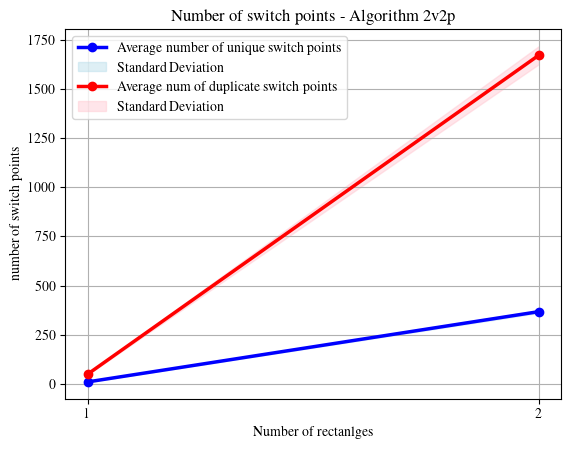

2v2u
[29.0, 610.0]
[1.0, 14.0]
[111.5, 2137.5]
[14.5, 44.5]


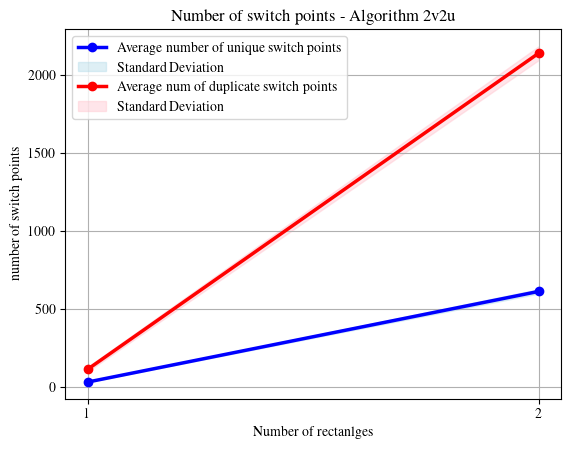

3v1
[58.5, 1563.0]
[2.5, 57.0]
[496.0, 11547.5]
[32.0, 137.5]


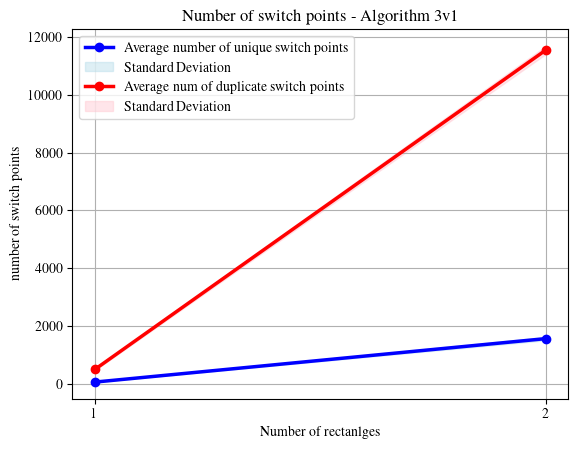

In [64]:
plot_switch_pts_rectangles(Omega_counts, algo_names, max_num, 0)
plot_switch_pts_rectangles(Omega_counts, algo_names, max_num, 1)
plot_switch_pts_rectangles(Omega_counts, algo_names, max_num, 2)

In [69]:
def plot_switch_pts_rectangles_total(Omega_counts,  max_num):
    """Plot the average number of switch points and the standard error of the mean""" 
    ## make plot with my data 
    omega_counts_total_u = {}
    omega_counts_total_d = {}

    for i in range(1, max_num+1):
        omega_counts_total_u[i] = Omega_counts[(i,'u')][0]+Omega_counts[(i,'u')][1]+Omega_counts[(i,'u')][2]
        omega_counts_total_d[i] = Omega_counts[(i,'d')][0]+Omega_counts[(i,'d')][1]+Omega_counts[(i,'d')][2]


    # Calculate averages and standard deviations
    averages_u = [np.mean(omega_counts_total_u[i]) for i in range(1, max_num+1)]


    print(averages_u)
    std_devs_u = [np.std(omega_counts_total_u[i]) for i in range(1, max_num+1)]
    std_sem_u = [scipy.stats.sem(omega_counts_total_u[i]) for i in range(1, max_num+1)]
    print(std_devs_u)
    

    averages_d = [np.mean(omega_counts_total_d[i]) for i in range(1, max_num+1)]
    std_devs_d = [np.std(omega_counts_total_d[i]) for i in range(1, max_num+1)]
    std_sem_d = [scipy.stats.sem(omega_counts_total_d[i]) for i in range(1, max_num+1)]
    print(averages_d)
    print(std_devs_d)
    # Plotting
    x = np.arange(1, max_num+1)  # Integers from 1 to 5

    plt.plot(x, averages_u, marker='o', linestyle='-', color='blue', linewidth=2.5, label='Average number of unique switch points')  # Thicker line for average

    plt.fill_between(x, np.array(averages_u) - np.array(std_sem_u), np.array(averages_u) + np.array(std_sem_u),
                    color='lightblue', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds

    plt.plot(x, averages_d, marker='o', linestyle='-', color='red', linewidth=2.5, label='Average num of duplicate switch points')  # Thicker line for average

    plt.fill_between(x, np.array(averages_d) - np.array(std_sem_d), np.array(averages_d) + np.array(std_sem_d),
                        color='pink', alpha=0.4, label='Standard Deviation')  # Fill between standard deviation bounds


    plt.xlabel('Number of rectanlges')
    plt.ylabel('number of switch points')
    plt.title('Number of switch points - All algorithms ')
    plt.xticks(x)
    plt.legend()
    plt.grid(True)
    plt.show()

[32.666666666666664, 846.8333333333334]
[19.84663419547226, 517.1177869263013]
[219.33333333333334, 5118.666666666667]
[198.25712821709308, 4550.701801798146]


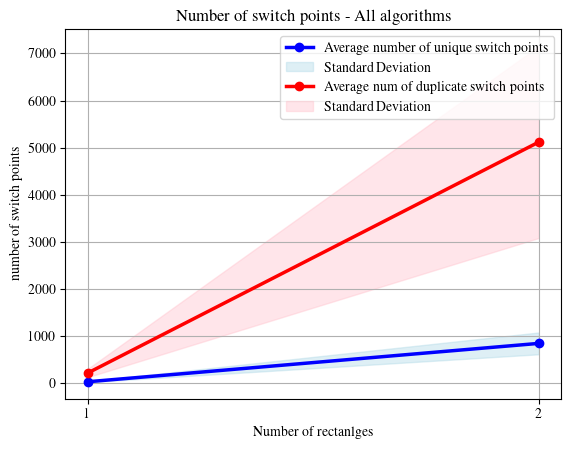

In [70]:
plot_switch_pts_rectangles_total(Omega_counts,  max_num)

In [ ]:
## plot ration of unique to duplicate switch points 

## To do: 
- load pickle file with the omega counts 
- run examples with poisson intensity 
- compute ratio of points 